# Strip waveguide directional coupler

In [2]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

%matplotlib widget

# Import modules
from datetime import datetime
import lumapi as lma
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [3]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [4]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |

In [5]:
# Si/SiO2/Si 500x220nm 1550nm
experiment_name = "si_h220nm_w500nm_dc_gsweep"

gap_sweep = np.arange(10*nm, 900*nm, 25*nm)

wavelength_center = 1.55*um

coupler_gap = 400*nm

core_thickness = 220*nm
core_width = 500*nm

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
core_material = "Si (Silicon) - Palik"
clad_material = "SiO2 (Glass) - Palik"
substrate_material = "Si (Silicon) - Palik"

In [6]:
# Si3n4/SiO2/Si 1000x220nm 1550nm
experiment_name = "si3n4_h360nm_w1000nm_dc_gsweep"

gap_sweep = np.arange(375*nm, 425*nm, 5*nm)

wavelength_center = 1.55*um

coupler_gap = 400*nm

core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
core_material = "Si3N4 (Silicon Nitride) - Luke"
clad_material = "SiO2 (Glass) - Palik"
substrate_material = "Si (Silicon) - Palik"

In [7]:
field_intensity_log_decay = -6
# initial_fde_height = 12 * core_thickness
# initial_fde_width = 5*(core_width + coupler_gap + core_width)

initial_fde_height = 8*um
initial_fde_width = 10*um

In [8]:
# Get solver
mode_solver = lma.MODE(hide=False)

In [9]:
# Materials fitting
mode_solver.switchtolayout()

def fit_material(material_name):
    wavelength_min = wavelength_center - 150*nm
    wavelength_max = wavelength_center + 150*nm

    try:
        mode_solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = mode_solver.copymaterial(material_name)
    mode_solver.setmaterial(material_fitted, "tolerance", 0.001)
    mode_solver.setmaterial(material_fitted, "max coefficients", 6)
    mode_solver.setmaterial(material_fitted, "specify fit range", True)
    mode_solver.setmaterial(material_fitted, "wavelength min", wavelength_min)
    mode_solver.setmaterial(material_fitted, "wavelength max", wavelength_max)
    mode_solver.setmaterial(material_fitted, "name", f"{material_name} Fitted")
    
    return f"{material_name} Fitted"

core_material = fit_material(core_material)
clad_material = fit_material(clad_material)
substrate_material = fit_material(substrate_material)

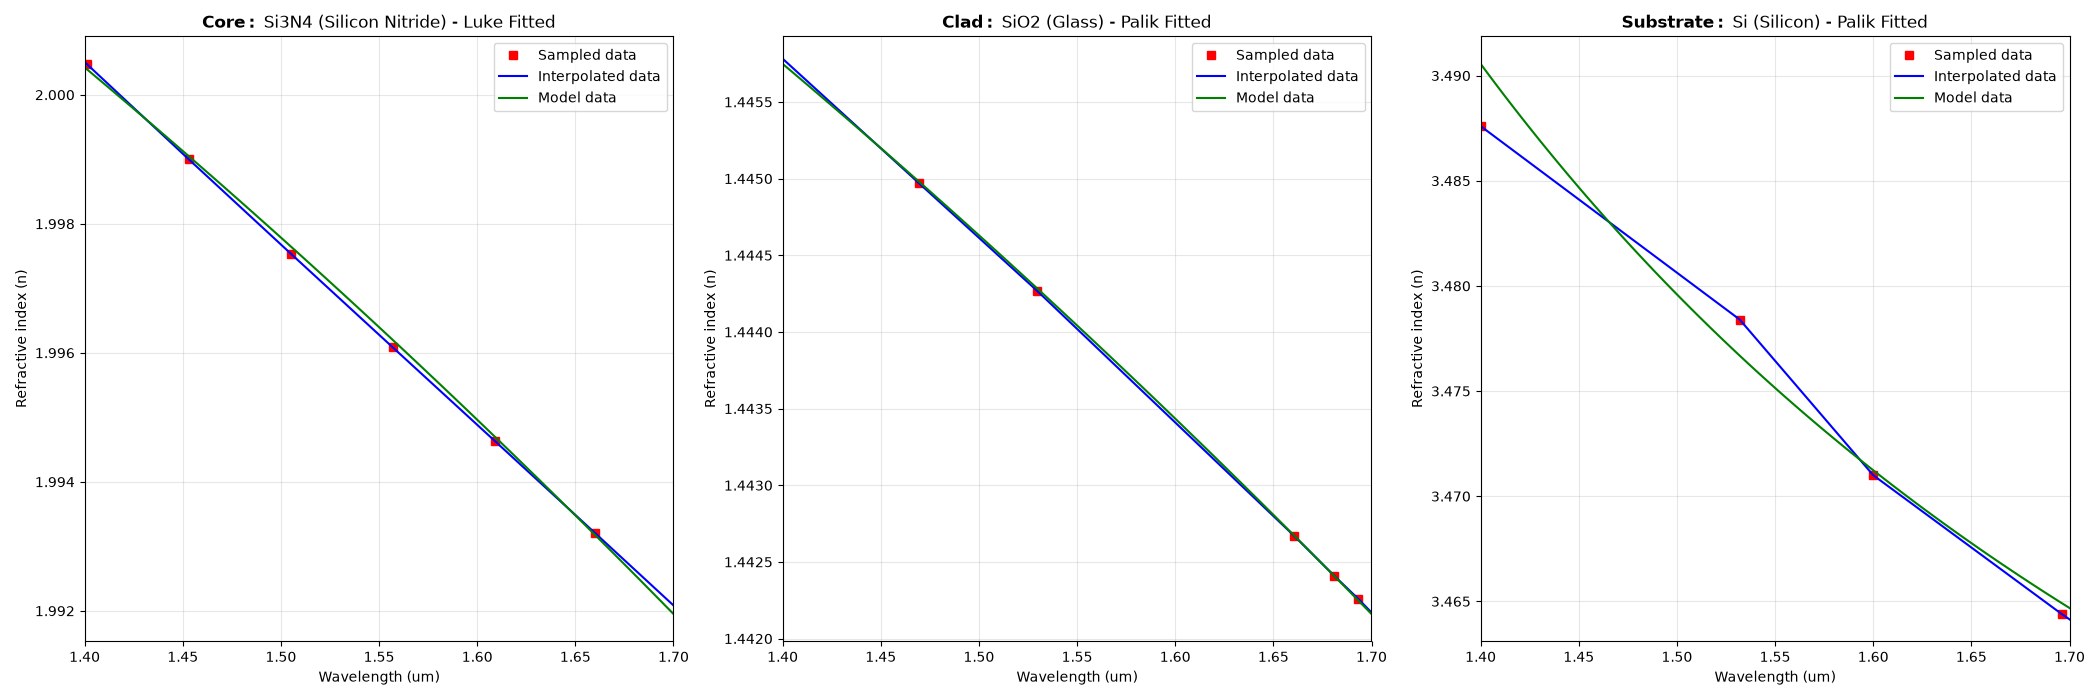

In [10]:
def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = mode_solver.getmaterial(material, "wavelength min")
    wvl_max = mode_solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = mode_solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = mode_solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = mode_solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

In [11]:
# Structure geometry
mode_solver.switchtolayout()
mode_solver.deleteall()

core1_x = -(core_width + coupler_gap)/2
core2_x = +(core_width + coupler_gap)/2
clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness

# Substrate
mode_solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=1*um,
    material=substrate_material,
    alpha=0.8,
)

# Clad
mode_solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=1*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

# Coupler group
mode_solver.addstructuregroup(name="coupler")

# Core 1
mode_solver.addrect(
    name="core1",
    x=core1_x, y=0, z=0,
    x_span=core_width, y_span=1*um, z_span=core_thickness,
    material=core_material,
)
mode_solver.addtogroup("coupler")

# Core 2
mode_solver.addrect(
    name="core2",
    x=core2_x, y=0, z=0,
    x_span=core_width, y_span=1*um, z_span=core_thickness,
    material=core_material,
)
mode_solver.addtogroup("coupler")


In [12]:
# Simulation setup

mode_solver.addfde(
    solver_type="2D Y Normal",
    x=0, x_span = initial_fde_width,
    y=0,
    z=0, z_span = initial_fde_height,
    number_of_trial_modes=10,
    wavelength=wavelength_center,
)

# Mesh override
mode_solver.addmesh(
    set_mesh_multiplier=True,
    x_mesh_multiplier=10,
    y_mesh_multiplier=10,
    z_mesh_multiplier=10,
    based_on_a_structure=True,
    structure="coupler",
    buffer=core_thickness/5, 
)

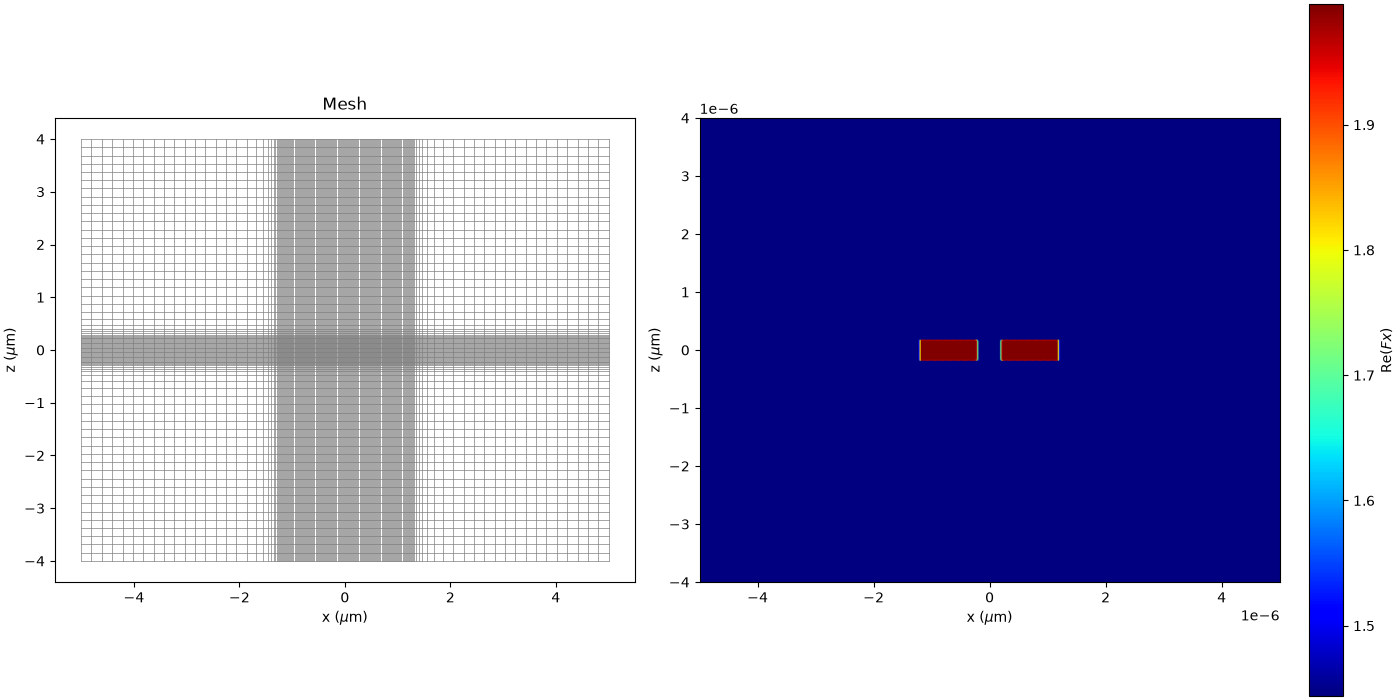

Current core width: 1000.0 nm
Current core height: 360.0 nm
Current coupler gap: 400.0 nm
Current fde width: 10.00 um
Current fde height: 8.00 um


In [13]:
# Simulation preview

mode_solver.mesh()
index = mode_solver.getresult("FDE::data::material", "index")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, z = np.squeeze(index["x"]), np.squeeze(index["z"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Z = np.meshgrid(x, z, indexing='ij')
ax1.plot(X * 1e6, Z * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Z.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'z ($\mu$m)')
ax1.set_aspect('equal')

px.plot_field(
    Fx=index_x,
    x=x, z=z,
    ax=ax2,
    scale="lin",
    # vmin=0,
    # vmax=5,
)
plt.show()

current_core_width = mode_solver.getnamed("coupler::core1", "x span")
current_core_height = mode_solver.getnamed("coupler::core1", "z span")
current_fde_width = mode_solver.getnamed("FDE", "x span")
current_fde_height = mode_solver.getnamed("FDE", "z span")

print(f"Current core width: {current_core_width*1e9:.1f} nm")
print(f"Current core height: {current_core_height*1e9:.1f} nm")
print(f"Current coupler gap: {coupler_gap*1e9:.1f} nm")
print(f"Current fde width: {current_fde_width*1e6:.2f} um")
print(f"Current fde height: {current_fde_height*1e6:.2f} um")

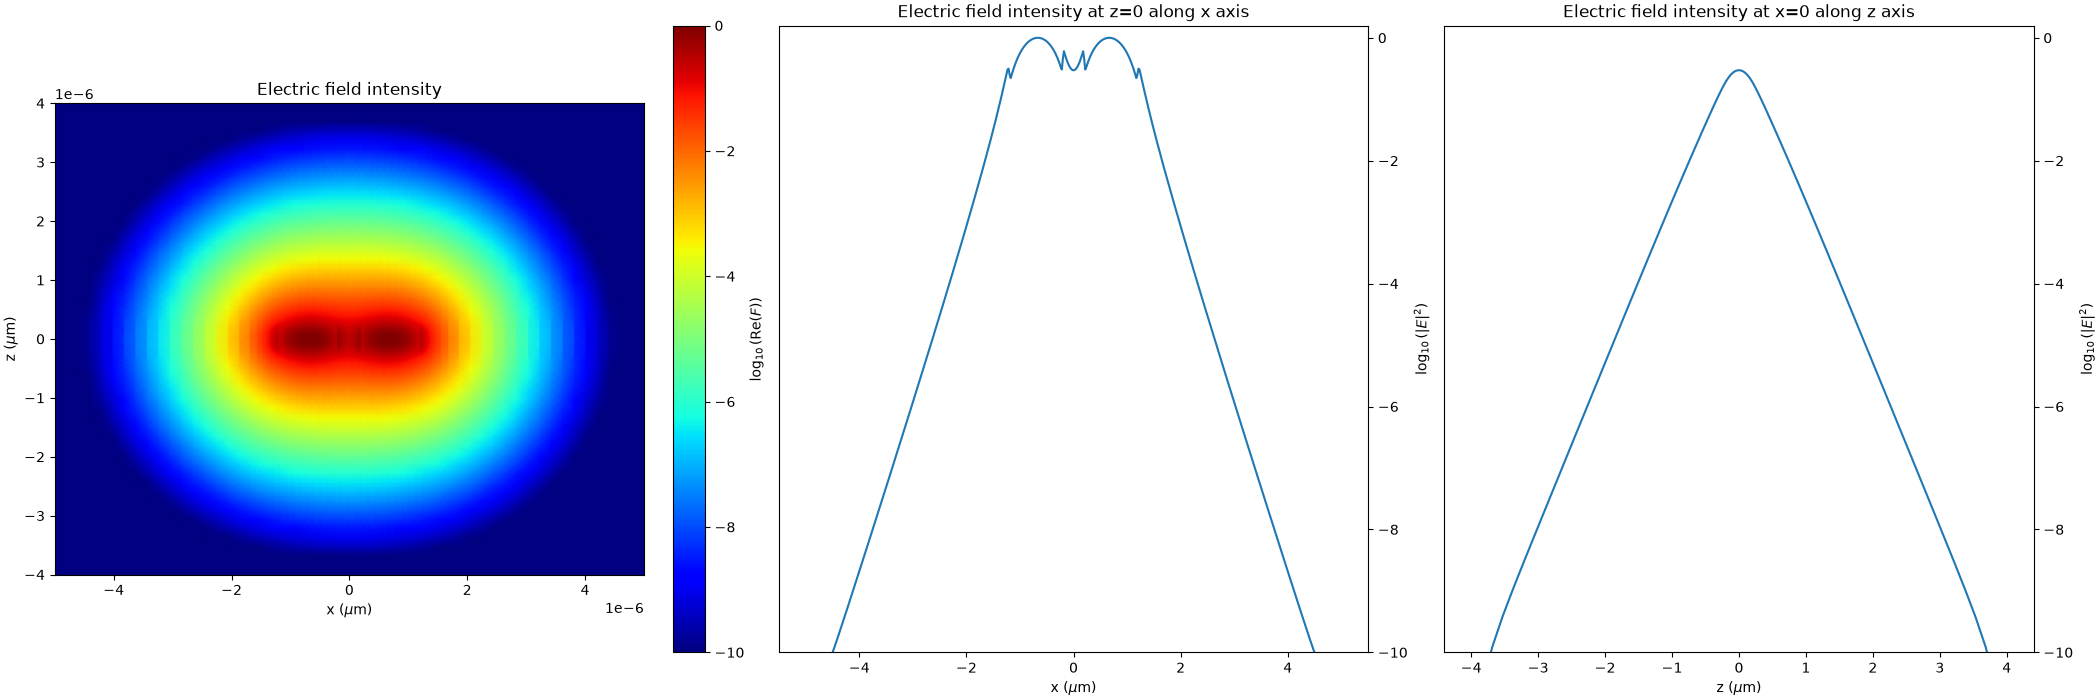

In [14]:
# Initial simulation

mode_solver.findmodes()

E = mode_solver.getresult("FDE::data::mode1", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
x, z = np.squeeze(E["x"]), np.squeeze(E["z"])

# decay = px.get_field_decay(Ex, Ey, Ez, margin=3)
# confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=initial_core_width)

# xmin = initial_core_width/2
# xmax = (initial_fde_width/2)*0.75
# slope_xp, intercept_xp = px.get_decay_slope(
#     Ex, Ey, Ez, 
#     x=x, 
#     amin=xmin,
#     amax=xmax,
# )

# zmin = core_thickness/2
# zmax = (initial_fde_height/2)*0.75
# slope_zp, intercept_zp = px.get_decay_slope(
#     Ex, Ey, Ez, 
#     z=z, 
#     amin=zmin,
#     amax=zmax,
# )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title('Electric field intensity')

# X decay
Eslice_x = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    x=x,
    scale="log"
)
ax2.plot(x*1e6, Eslice_x)
ax2.set_title('Electric field intensity at z=0 along x axis')
ax2.set_xlabel(r'x ($\mu$m)')
ax2.set_ylabel(r'$\log_{10}(|E|^2)$')
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.set_ylim(-10, 0.2)

# # X Decay fit
# y = slope_xp * x + intercept_xp
# ax2.plot(
#     x*1e6, y,
#     color='red', 
#     linestyle='--', 
#     linewidth=1.5, 
#     label=f'Decay fit'
# )
# ax2.legend(loc='upper right')

# Z decay
Eslice_z = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    z=z,
    scale="log"
)
ax3.plot(z*1e6, Eslice_z)
ax3.set_title('Electric field intensity at x=0 along z axis')
ax3.set_xlabel(r'z ($\mu$m)')
ax3.set_ylabel(r'$\log_{10}(|E|^2)$')
ax3.yaxis.tick_right()
ax3.yaxis.set_label_position("right")
ax3.set_ylim(-10, 0.2)

# # Z Decay fit
# y = slope_zp * z + intercept_zp
# ax3.plot(
#     z*1e6, y,
#     color='red', 
#     linestyle='--', 
#     linewidth=1.5, 
#     label=f'Decay fit'
# )
# ax3.legend(loc='upper right')

plt.show()

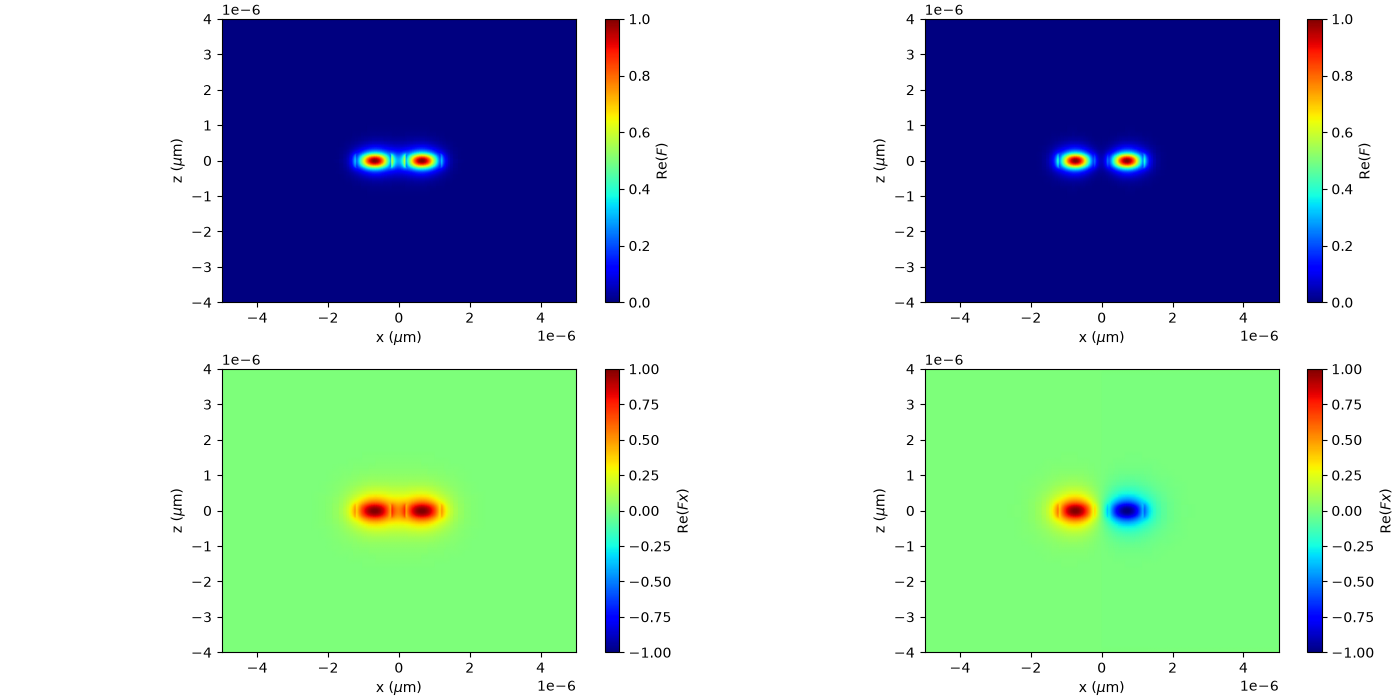

In [15]:
# Supermodes

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 7), constrained_layout=True)

E = mode_solver.getresult("FDE::data::mode1", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
x, z = np.squeeze(E["x"]), np.squeeze(E["z"])

px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    ax=ax1,
    scale="lin"
)

px.plot_field(
    Ex, 
    x=x, z=z,
    ax=ax3,
    vmin=-1, vmax=1,
    scale="lin"
)

E = mode_solver.getresult("FDE::data::mode2", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
x, z = np.squeeze(E["x"]), np.squeeze(E["z"])

px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    ax=ax2,
    scale="lin"
)

px.plot_field(
    Ex, 
    x=x, z=z,
    ax=ax4,
    vmin=-1, vmax=1,
    scale="lin"
)


plt.show()

## Gap Sweep

In [16]:
def update_gap_width(mode_solver, coupler_gap):
    core1_x = -(core_width + coupler_gap)/2
    core2_x = +(core_width + coupler_gap)/2

    mode_solver.switchtolayout()
    mode_solver.setnamed("coupler::core1", "x", core1_x)
    mode_solver.setnamed("coupler::core2", "x", core2_x)

def get_mode_data(mode_solver, mode_name):
    mode_data = {
        "f": mode_solver.getdata(mode_name, "f"),
        "neff": mode_solver.getdata(mode_name, "neff").item(),
        "ng": mode_solver.getdata(mode_name, "ng").item(),
        "loss": mode_solver.getdata(mode_name, "loss"),
        "TE polarization fraction": mode_solver.getdata(mode_name, "TE polarization fraction"),
        "waveguide TE-TM fraction": mode_solver.getdata(mode_name, "waveguide TE-TM fraction"),
        "mode effective area": mode_solver.getdata(mode_name, "mode effective area"),

        "x": mode_solver.getdata(mode_name, "x"),
        "y": mode_solver.getdata(mode_name, "y"),
        "z": mode_solver.getdata(mode_name, "z"),

        "Ex": mode_solver.getdata(mode_name, "Ex"),
        "Ey": mode_solver.getdata(mode_name, "Ex"),
        "Ez": mode_solver.getdata(mode_name, "Ex"),

        "Hx": mode_solver.getdata(mode_name, "Hx"),
        "Hy": mode_solver.getdata(mode_name, "Hy"),
        "Hz": mode_solver.getdata(mode_name, "Hz"),
    }
    
    return mode_data

In [17]:
sweep_data = []
for i, g in enumerate(reversed(gap_sweep)):
    # Update core width
    update_gap_width(mode_solver, g)

    # Find modes
    mode_solver.findmodes()
    mode1_data = get_mode_data(mode_solver, "FDE::data::mode1")
    mode2_data = get_mode_data(mode_solver, "FDE::data::mode2")

    sweep_data.append({
        "coupler_gap": g,
        "modes": [mode1_data, mode2_data ],
    })

**Cross-over length**: $L_x = \frac{\lambda_0}{2 \cdot \Delta n_{\text{eff}}}$.

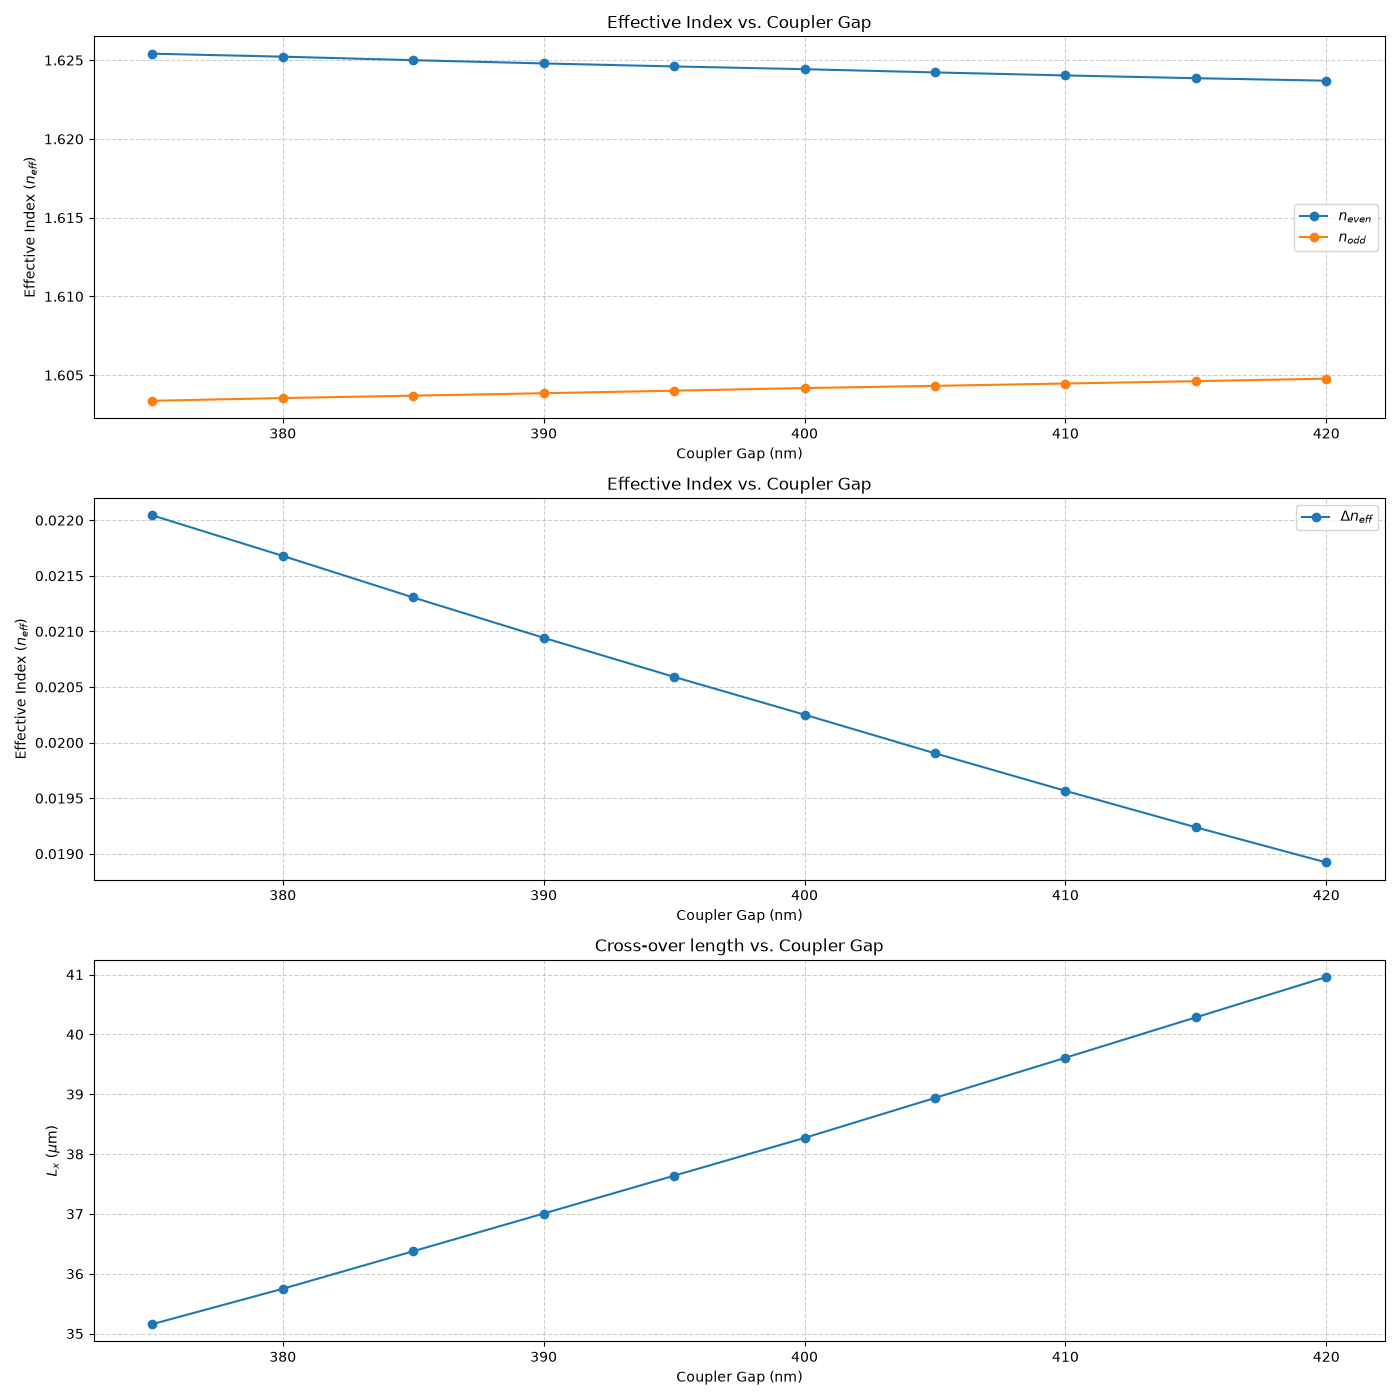

In [19]:
gaps_nm = np.array([step["coupler_gap"] * 1e9 for step in sweep_data])
neffs_matrix = np.full((len(sweep_data), 2), np.nan)

calc_delta = lambda n1, n2: n1 - n2
calc_lx = lambda wvl0, delta_n: (wvl0/(2*delta_n))
calc_k = lambda wvl0, delta_n, l: np.sin(((np.pi*delta_n)/wvl0)*l)
calc_t = lambda wvl0, delta_n, l: np.cos(((np.pi*delta_n)/wvl0)*l)

for i, step in enumerate(sweep_data):
    sorted_modes = sorted(step["modes"], key=lambda m: np.real(m["neff"]), reverse=True)
    for m_idx, mode in enumerate(sorted_modes[:2]):
        neffs_matrix[i, m_idx] = np.real(mode["neff"])

ns_even = neffs_matrix[:, 0]
ns_odd = neffs_matrix[:, 1]
deltas_n = calc_delta(ns_even, ns_odd)
lxs = calc_lx(wavelength_center, deltas_n)
lxs_um = lxs*1e6

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 14))

# Even modes
ax1.plot(
    gaps_nm,
    ns_even,
    marker="o",
    linestyle="-",
    label="$n_{even}$",
)

# Odd modes
ax1.plot(
    gaps_nm,
    ns_odd,
    marker="o",
    linestyle="-",
    label="$n_{odd}$",
)

ax1.set_title("Effective Index vs. Coupler Gap")
ax1.set_xlabel("Coupler Gap (nm)")
ax1.set_ylabel("Effective Index ($n_{eff}$)")
ax1.legend(fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.6)

# Delta n
ax2.plot(
    gaps_nm,
    deltas_n,
    marker="o",
    linestyle="-",
    label=r"$\Delta n_{eff}$",
)

ax2.set_title("Effective Index vs. Coupler Gap")
ax2.set_xlabel("Coupler Gap (nm)")
ax2.set_ylabel("Effective Index ($n_{eff}$)")
ax2.legend(fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)

ax3.plot(
    gaps_nm,
    lxs_um,
    marker="o",
    linestyle="-",
)

ax3.set_title("Cross-over length vs. Coupler Gap")
ax3.set_xlabel("Coupler Gap (nm)")
ax3.set_ylabel(r"$L_x$ ($\mu$m)"),
ax3.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

Gap: 400.0 nm


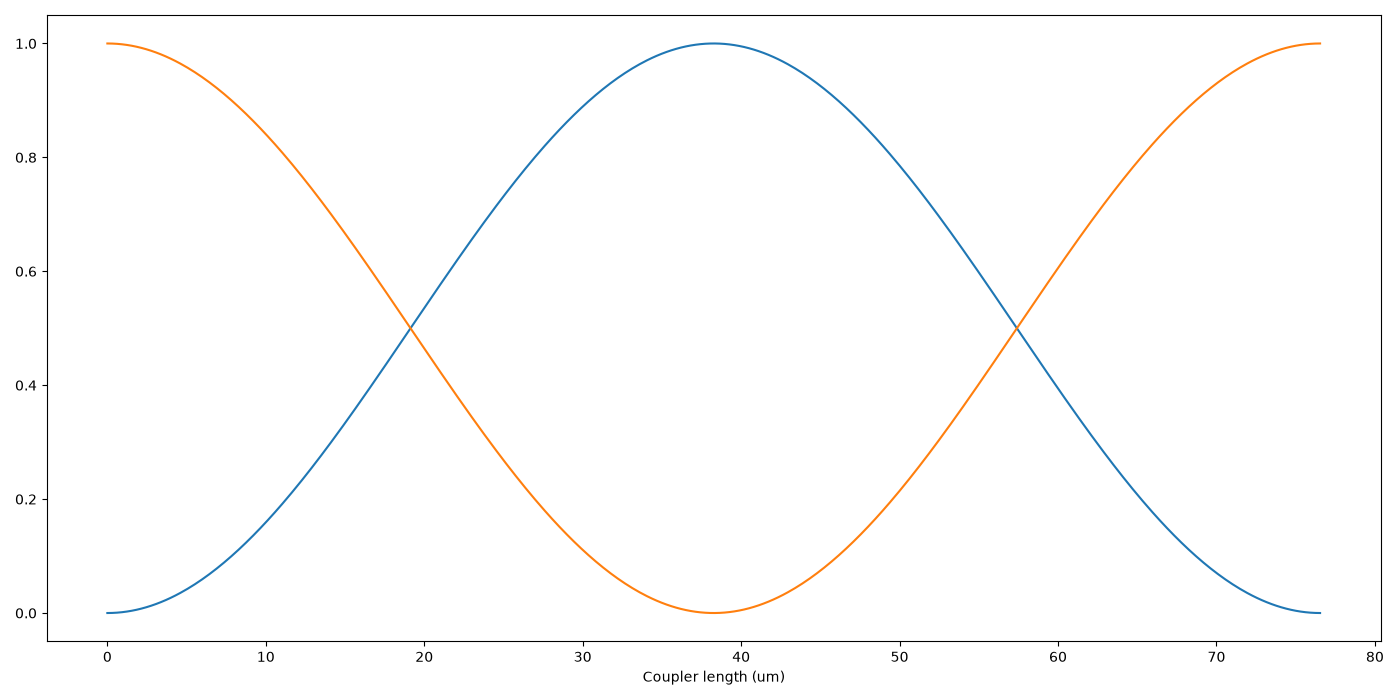

In [21]:
coupler_gap = [400.0]
g_idx = np.argmin(np.abs(gaps_nm - coupler_gap))
print(f"Gap: {gaps_nm[g_idx]:.1f} nm")
delta_n = deltas_n[g_idx]

lx = calc_lx(wavelength_center, delta_n)
ls = np.linspace(0, lx*2, 500)
ls_um = ls * 1e6

k2s = calc_k(wavelength_center, delta_n, ls)**2
t2s = calc_t(wavelength_center, delta_n, ls)**2

fig, ax1 = plt.subplots(1, 1, figsize=(14, 7))

ax1.plot(
    ls_um,
    k2s,
)

ax1.plot(
    ls_um,
    t2s,
)

ax1.set_xlabel("Coupler length (um)")
plt.tight_layout()
plt.show()